# 13 · Does the chosen system transfer, and does it age?

**The questions.** Two checks before the chosen design is built (DESIGN_QUESTIONS C6, C4 and B1):
1. **Transfer (C6).** The ensemble (XGBoost and a 100-tree random forest, rank-averaged; notebooks 10–12) was chosen on 2011 line items from every region. Does the choice hold when the model meets a region it never trained on?
2. **Time (C4, B1).** WildGuard scores CITES for 2015–2024 with a model trained on 2000–2010. How much does performance fall as the gap between the training years and the scored year grows? B1 decides from this whether the deployed model is refitted on all of 2000–2014.

**Fixed before looking:**
- **Transfer.** Five regional holdouts, as in notebook 08: train on line items exported from the other regions, 2000–2010, with peer norms from those line items (S2.1), and score the held-out region's 2011 line items. On listed line items, compare the ensemble with XGBoost alone. **Rule:** the ensemble is deployed only if it is not significantly worse than XGBoost alone on any holdout (95% paired-bootstrap interval of the difference entirely below zero); otherwise WildGuard falls back to XGBoost alone. The old pipeline's XGBoost (depth 8, learning rate 0.08, square-root class weight, 326 rounds) is reported alongside, not deciding.
- **Time.** Four training windows of five years, 2000–2004, 2002–2006, 2004–2008 and 2006–2010, each scored on the same year, 2011, so the test set is fixed and only the gap changes (7, 5, 3 and 1 years). **Rule (B1):** if PR-AUC on listed 2011 line items is significantly lower for the 7-year gap than for the 1-year gap, the deployed model is refitted on all of 2000–2014; otherwise the tested model (2000–2010) is deployed.
- All on 2011 (the selection year); 2012–2014 are not used. The bootstrap resamples shipments.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

import eda_setup as E
import experiment_setup as X_
import model_selection as M
from wildguard import config
from wildguard.features import SHARED_FEATURES as FEATS, FeatureBuilder

E.style()
t0 = time.time()
df = X_.load_lemis()
df = df[df["animal"]].reset_index(drop=True)
yr, reg, y = df["year"].to_numpy(), df["exporter_region"].to_numpy(), df["label"].to_numpy()
search = pd.read_parquet(config.PROCESSED_DIR / "experiments" / "model_search.parquet")
row = search[(search.candidate == "xgboost") & (search.config == 5)].iloc[0]
XGB_CFG, XGB_ROUNDS = M.config_from_row(row.to_dict()), int(row["best_rounds"])
OLD_CFG = {"imbalance": "class_weight", "max_depth": 8, "learning_rate": 0.08, "subsample": 0.8,
           "colsample_bytree": 0.8, "min_child_weight": 5.0}
rk = lambda s: pd.Series(s).rank(pct=True).to_numpy()


def train_and_score(train, target, old=False):
    """Fit norms and models on `train`, score `target`. Returns a dict of score arrays."""
    fb = FeatureBuilder(use_value=False).fit(df[train])
    F_tr, F_tg = fb.transform(df[train]), fb.transform(df[target])
    base = M.Base().fit(F_tr, FEATS)
    Xtr, Xtg = base.transform(F_tr), base.transform(F_tg)
    enc = M.Native(base).fit(Xtr)
    ytr = y[train]
    out = {"XGBoost": M.build_model("xgboost", XGB_CFG, enc, ytr, 37, XGB_ROUNDS)
           .fit(enc.transform(Xtr), ytr).predict_proba(enc.transform(Xtg))[:, 1]}
    rf = RandomForestClassifier(n_estimators=100, max_depth=16, min_samples_leaf=5, max_features="sqrt",
                                n_jobs=8, random_state=37).fit(Xtr, ytr)
    out["ensemble"] = (rk(out["XGBoost"]) + rk(rf.predict_proba(Xtg)[:, 1])) / 2
    if old:
        out["old pipeline XGBoost"] = (M.build_model("xgboost", OLD_CFG, enc, ytr, 37, 326)
                                       .fit(enc.transform(Xtr), ytr).predict_proba(enc.transform(Xtg))[:, 1])
    return out

## 1. Transfer to regions the model never saw (C6)

In [2]:
rows = []
for r in ("Asia", "Europe", "Americas", "Africa", "Oceania"):
    train, target = (reg != r) & (yr <= 2010), (reg == r) & (yr == 2011)
    s = train_and_score(train, target, old=True)
    t = df[target]
    m = t["sp_listed"].to_numpy()
    b = X_.pr_auc_bootstrap(t["label"].to_numpy()[m], {k: v[m] for k, v in s.items()},
                            t["shipment_id"].to_numpy()[m],
                            [("ensemble", "XGBoost"), ("ensemble", "old pipeline XGBoost")])
    rows.append(b.assign(holdout=r))
    print(f"{r}: done ({time.time() - t0:.0f}s)", flush=True)
reg_res = pd.concat(rows)
display(reg_res.set_index(["holdout", "b"])[["pr_auc_a", "pr_auc_b", "difference", "low_95", "high_95"]]
        .rename(columns={"pr_auc_a": "PR-AUC ensemble", "pr_auc_b": "PR-AUC compared model"})
        .style.format("{:.3f}"))
worse = reg_res[(reg_res.b == "XGBoost") & (reg_res.high_95 < 0)].holdout.tolist()
DEPLOY_ENSEMBLE = not worse
print("Holdouts where the ensemble is significantly worse than XGBoost alone:", worse or "none")
print("Decision:", "the ensemble passes the transfer check" if DEPLOY_ENSEMBLE else "fall back to XGBoost alone")

Asia: done (89s)


Europe: done (198s)


Americas: done (300s)


Africa: done (412s)


Oceania: done (534s)


Holdouts where the ensemble is significantly worse than XGBoost alone: none
Decision: the ensemble passes the transfer check


## 2. How performance ages (C4, B1)

window 2000-2004: done (572s)


window 2002-2006: done (617s)


window 2004-2008: done (670s)


window 2006-2010: done (722s)


,a,b,pr_auc_a,pr_auc_b,difference,low_95,high_95
0,gap 1 years (2006–2010),gap 7 years (2000–2004),0.570,0.512,0.059,0.049,0.069
1,gap 1 years (2006–2010),gap 5 years (2002–2006),0.570,0.528,0.042,0.034,0.051
2,gap 1 years (2006–2010),gap 3 years (2004–2008),0.570,0.536,0.035,0.029,0.041


Decision: refit the deployed model on 2000-2014


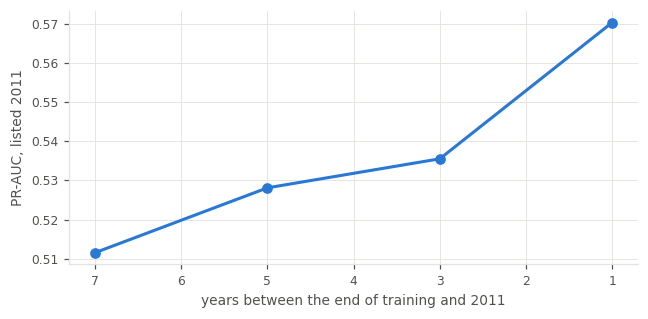

In [3]:
windows = {7: (2000, 2004), 5: (2002, 2006), 3: (2004, 2008), 1: (2006, 2010)}
target = yr == 2011
t = df[target]
m = t["sp_listed"].to_numpy()
age = {}
for gap, (a, b) in windows.items():
    age[f"gap {gap} years ({a}–{b})"] = train_and_score((yr >= a) & (yr <= b), target)["ensemble"][m]
    print(f"window {a}-{b}: done ({time.time() - t0:.0f}s)", flush=True)
names = list(age)
age_res = X_.pr_auc_bootstrap(t["label"].to_numpy()[m], age, t["shipment_id"].to_numpy()[m],
                              [(names[-1], n) for n in names[:-1]])
display(age_res.style.format({c: "{:.3f}" for c in ("pr_auc_a", "pr_auc_b", "difference", "low_95", "high_95")}))
pr = {n: average_precision_score(t["label"].to_numpy()[m], s) for n, s in age.items()}
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(list(windows), [pr[n] for n in names], "o-", color=E.LEMIS_C)
ax.set_xlabel("years between the end of training and 2011")
ax.set_ylabel("PR-AUC, listed 2011")
ax.invert_xaxis()
plt.tight_layout()
longest = age_res[age_res.b == names[0]].iloc[0]
REFIT = bool(longest["low_95"] > 0)
print("Decision:", "refit the deployed model on 2000-2014" if REFIT else "deploy the tested model (2000-2010)")

## Findings

| # | Finding |
|---|---|
| R1 | **Transfer.** On no held-out region is the ensemble significantly worse than XGBoost alone (differences −0.023 to +0.006 on listed 2011 line items). The closest calls are Africa (−0.023, interval −0.053 to +0.003) and Oceania (−0.021, interval −0.060 to +0.011), the two smallest holdouts. The ensemble passes |
| R2 | **Against the old pipeline's XGBoost** (depth 8, square-root class weight), the ensemble is significantly better on Europe (+0.019) and the Americas (+0.057), and not significantly different on Asia, Africa and Oceania |
| R3 | **Ageing.** Scored on the same year (2011), five-year training windows ending 1, 3, 5 and 7 years earlier reach PR-AUC 0.570, 0.536, 0.528 and 0.512 on listed line items: the 1-year gap beats the 7-year gap by 0.059 (interval 0.049 to 0.069) |
| R4 | The decline is not only a matter of data volume: the windows 2004–2008 and 2006–2010 hold almost the same number of line items (about 1.87 and 1.88 million), yet differ by 0.035 |
| R5 | **For CITES:** the scored years are 1 to 10 years after LEMIS ends, so the ranking is likely weaker for the later CITES years. This is a limitation of the transfer, not something CITES data can measure |

**Decisions (31 October 2026):**
- **C6:** the ensemble passes the transfer check and is deployed.
- **B1:** performance falls with the gap, so the deployed model is refitted on all of 2000–2014 after the one test. The report states that the deployed model differs from the tested one in its training years only.